# 5 · Ses modalitesi (Kriter 5 ve 6)

**Sorular:** Ses verisi tam olarak ne? Değerler nasıl dağılıyor ve neden logaritma aldık? Sınıflar arasında fark var mı?
Gürültü ve eksik mikrofon var mı?

**Ses verisi:** Gerçek kayıt değil, gizlilik için yazarların ürettiği **ses zarfı**: 10 saniyede 800 sayı, her biri o anki ses
şiddeti. Konuşma anlaşılmaz; yalnız "ne kadar ses var, ne zaman" bilgisi kalır.

**Kurulum hücresi.** Önce bunu çalıştır (ya da Run → Run All). Kütüphaneleri, projenin `src/` kodlarını ve
etiketleri yükler; sonraki hücreler buradaki isimleri kullanır.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))           # projenin kendi kodları (src/) buradan çağrılır
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from build import OUT, INTERIM, ENV_COLS, HOMES, hubs_of
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
CLS = ["0 kişi", "1 kişi", "2+ kişi"]; RENK = ["#2A78D6", "#EB6834", "#1BAF7A"]   # bütün grafiklerde aynı renkler
LAB = {h: pd.read_parquet(OUT / h / "labels.parquet") for h in HOMES}           # etiketler (her ev için 10 sn ızgara)
print("evler:", HOMES, "| toplam pencere:", sum(map(len, LAB.values())))

evler: ['H1', 'H2', 'H3', 'H4', 'H5', 'H6'] | toplam pencere: 1311925


## 5.1 Ham zarf ve log dönüşümü

Diskte `log1p(ham)` = log(1 + ham) saklanıyor (`src/build.py`). Neden: ham değerler yüzlerden yüz milyonlara uzanıyor;
birkaç dev değer, modelin öğrenmesini (gradyanları) domine ederdi.

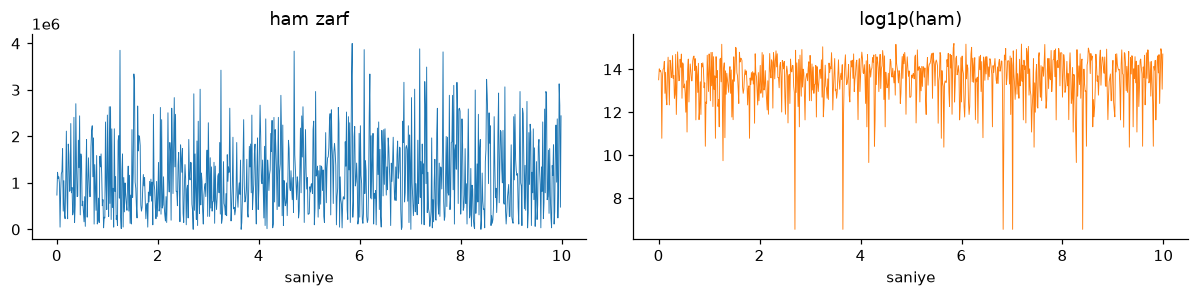

In [2]:
S = ROOT / "data" / "samples" / "H1" / "H1_RS2_AUDIO" / "2019-11-26" / "1700"
raw = np.loadtxt(S / "2019-11-26_170000_RS2_H1.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].plot(np.arange(800) / 80, raw, lw=0.6); ax[0].set_title("ham zarf"); ax[0].set_xlabel("saniye")
ax[1].plot(np.arange(800) / 80, np.log1p(raw), lw=0.6, color="C1"); ax[1].set_title("log1p(ham)"); ax[1].set_xlabel("saniye")
plt.tight_layout(); plt.show()

ham: medyan 321,157, en büyük 585,220,934, çarpıklık 49.0


log: medyan 12.68, en büyük 20.19, çarpıklık -0.69


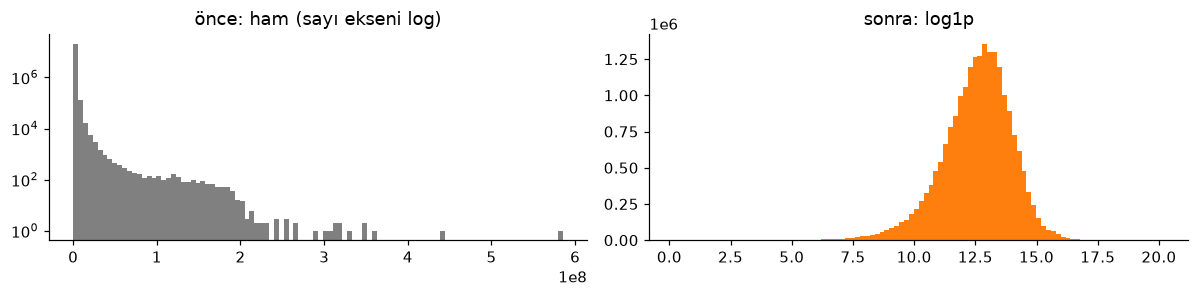

In [3]:
# Bütün evlerden örneklem: her hub'dan her 200. sesli pencere, her pencereden 800 değer
vals = []
for h in HOMES:
    for hub in hubs_of(h):
        ok = pd.read_parquet(OUT / h / f"{hub}_aud.parquet")["aud_ok"].to_numpy()
        idx = np.flatnonzero(ok)[::200]
        if len(idx): vals.append(np.load(OUT / h / f"{hub}_aud.npy", mmap_mode="r")[idx].astype("float64").ravel())
logv = pd.Series(np.concatenate(vals)); rawv = np.expm1(logv)
print(f"ham: medyan {rawv.median():,.0f}, en büyük {rawv.max():,.0f}, çarpıklık {rawv.skew():.1f}")
print(f"log: medyan {logv.median():.2f}, en büyük {logv.max():.2f}, çarpıklık {logv.skew():.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].hist(rawv, bins=100, color="gray"); ax[0].set_yscale("log"); ax[0].set_title("önce: ham (sayı ekseni log)")
ax[1].hist(logv, bins=100, color="C1"); ax[1].set_title("sonra: log1p"); plt.tight_layout(); plt.show()

**Öncesi–sonrası:** Çarpıklık (tek tarafa uzun kuyruk ölçüsü; 0 = simetrik) ~51'den ~−0,7'ye iniyor. Dağılım neredeyse
simetrik. Modele girerken ayrıca hub içi z-skoru uygulanıyor (her mikrofonun kendi ortalamasına göre).

## 5.2 Eksik ses: hangi mikrofonlar çalışmamış?

In [4]:
R = {}
for h in HOMES:
    for hub in hubs_of(h):
        a = pd.read_parquet(OUT / h / f"{hub}_aud.parquet")
        R[f"{h}-{hub}"] = {"sesi olan pencere %": 100 * a["aud_ok"].mean(), "uzunluk 800 olmayan": int(((a["aud_len"] != 800) & a["aud_ok"]).sum())}
R = pd.DataFrame(R).T.round(1); R.sort_values("sesi olan pencere %").head(6)

,sesi olan pencere %,uzunluk 800 olmayan
H6-BS2,0.0,0.0
H5-RS1,22.1,0.0
H4-RS1,83.7,0.0
H4-RS4,86.2,0.0
H5-RS4,86.4,0.0
H5-RS5,89.0,0.0


H6-BS2'de hiç ses yok, H5-RS1'de çok az: donanım kesintisi (yazarların metadata'sıyla aynı). Uzunluğu 800 olmayan dosya
yok → kırpma/doldurma gerekmiyor. Eksik ses pencereleri silinmiyor, maskeleniyor.

## 5.3 Sınıflar arasında ses farkı var mı?

Pencere başına ortalama log-enerji, hub içi z-skoruna çevrilmiş (0 = o mikrofonun normali).

,mean,50%,std
sınıf,,,
0 kişi,-0.05,-0.06,0.90
1 kişi,0.01,-0.04,1.05
2+ kişi,0.03,0.12,1.03


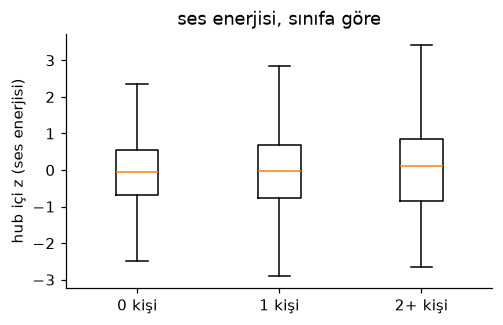

In [5]:
E = []
for h in HOMES:
    y = LAB[h]["cls"].to_numpy()
    for hub in hubs_of(h):
        ok = pd.read_parquet(OUT / h / f"{hub}_aud.parquet")["aud_ok"].to_numpy(); idx = np.flatnonzero(ok)[::20]
        if not len(idx): continue
        e = np.load(OUT / h / f"{hub}_aud.npy", mmap_mode="r")[idx].astype("float32").mean(1)
        E.append(pd.DataFrame({"z": (e - e.mean()) / e.std(), "sınıf": y[idx]}))
E = pd.concat(E)
display(E.groupby("sınıf")["z"].describe()[["mean", "50%", "std"]].round(2).rename(index=dict(enumerate(CLS))))
plt.figure(figsize=(5, 3)); plt.boxplot([E.loc[E["sınıf"] == c, "z"] for c in range(3)], tick_labels=CLS, showfliers=False)
plt.ylabel("hub içi z (ses enerjisi)"); plt.title("ses enerjisi, sınıfa göre"); plt.show()

**Gözlem:** Medyanlar sıfıra çok yakın, kutular üst üste: ses enerjisi tek başına sınıfı zayıf ayırıyor. 2+ biraz daha
yüksek. **Modele etkisi:** ses tek başına zayıf bir modalite; diğerleriyle birleşince anlamlı.

## 5.4 Neden zayıf? Tekrarlayan arka plan sesi

Tek bir günün dakikalık ses enerjisi ve otokorelasyonu (sinyalin kendisiyle kaydırılmış hâlinin benzerliği; tekrarlanan bir
desen varsa o gecikmede tepe yapar).

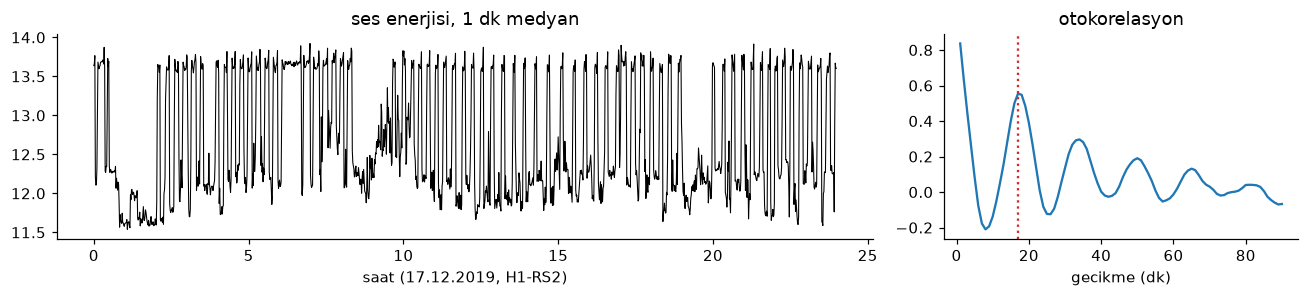

en güçlü tekrar: ~17 dakikada bir


In [6]:
i0 = int(np.flatnonzero(LAB["H1"]["ts"] == "2019-12-17 00:00:00")[0]); n = 8640
e = np.load(OUT / "H1/RS2_aud.npy", mmap_mode="r")[i0:i0 + n].astype("float32").mean(1)
ok = pd.read_parquet(OUT / "H1/RS2_aud.parquet")["aud_ok"].to_numpy()[i0:i0 + n]
e[~ok] = np.nan                                                    # sesi olmayan pencere 0 değil, boş
dak = pd.Series(e).groupby(np.arange(n) // 6).median().interpolate()   # 1 dakikalık medyan
ac = [dak.autocorr(k) for k in range(1, 91)]
fig, ax = plt.subplots(1, 2, figsize=(12, 2.8), gridspec_kw={"width_ratios": [3, 1.3]})
ax[0].plot(dak.index / 60, dak, lw=0.7, color="k"); ax[0].set_xlabel("saat (17.12.2019, H1-RS2)"); ax[0].set_title("ses enerjisi, 1 dk medyan")
ax[1].plot(range(1, 91), ac); ax[1].set_xlabel("gecikme (dk)"); ax[1].set_title("otokorelasyon")
k = int(np.argmax(ac[9:]) + 10); ax[1].axvline(k, color="C3", ls=":"); plt.tight_layout(); plt.show()
print(f"en güçlü tekrar: ~{k} dakikada bir")

**Yorum:** Gün boyu, gece de dahil, düzenli kare dalgalar var; otokorelasyon yaklaşık 17 dakikada tepe yapıyor, yani o sıklıkta tekrarlıyor. İnsanla ilgisi yok;
büyük olasılıkla ısıtma/klima döngüsü (doğrulanmadı). Sesin büyük kısmı bu arka plan. **Final planı:** kayan medyanla arka
plan çıkarma denenecek.